# Week 5 Part C ? The two-map activity, on real readers

This notebook builds two maps from `county_crime.csv`: raw crimes reported and crimes per 100,000 residents. Both use the same district boundaries, five-class scheme, and sequential ramp. The only analytical difference is the denominator.

The reader study is deliberately not fabricated. Run the recording cell while showing Map A and Map B to at least five real readers, in the required order, and save their answers to `partC_reader_results.csv`.


In [22]:
from pathlib import Path
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, Normalize
from matplotlib.cm import ScalarMappable
from scipy import stats

try:
    import seaborn as sns
    sns.set_theme(style='whitegrid', context='notebook')
except ImportError:
    plt.style.use('seaborn-v0_8-whitegrid')

BASE=Path.cwd()
if not (BASE/'county_crime.csv').exists() and (BASE/'Week5').exists(): BASE=BASE/'Week5'
crime=pd.read_csv(BASE/'county_crime.csv')
with open(BASE/'districts.geojson',encoding='utf-8') as f: geo=json.load(f)
features=geo['features']
geo_codes={f['properties']['code']:f for f in features}
print('Data directory:',BASE,'| counties:',len(crime),'| geometries:',len(features))


Data directory: d:\University\ML Lab\Week5 | counties: 20 | geometries: 24


## 1. Build both maps

The county table contains D01?D20, while the geometry contains D01?D24. The four unmatched polygons D21?D24 are excluded because no county record exists for them. The join check is printed before drawing.

Natural breaks are implemented as five ordered classes using sorted-data partitions; the same break-generation procedure and the same `Blues` ramp are used for both maps. Breaks are printed on each figure so the classification is auditable.


Matched counties: 20 | county rows without geometry: [] | geometry polygons without county rows: ['D21', 'D22', 'D23', 'D24'] (left out)
Pearson r(crimes_reported, population): 0.935
Map A: crimes reported (raw count) class breaks: [  88.  152.  384.  562. 1952. 5971.]


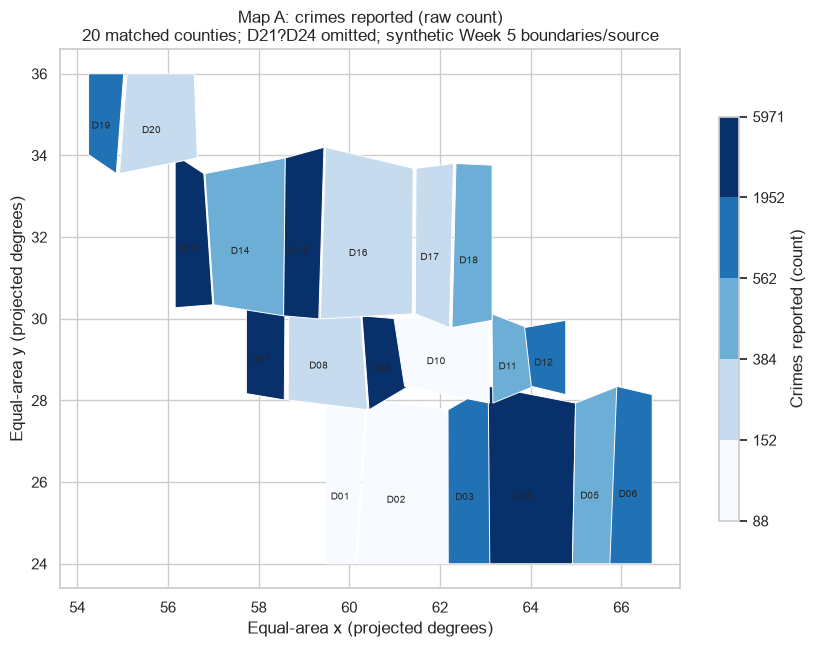

Map B: crimes per 100,000 residents class breaks: [ 479.17  612.95  773.55 1272.73 1624.6  1800.  ]


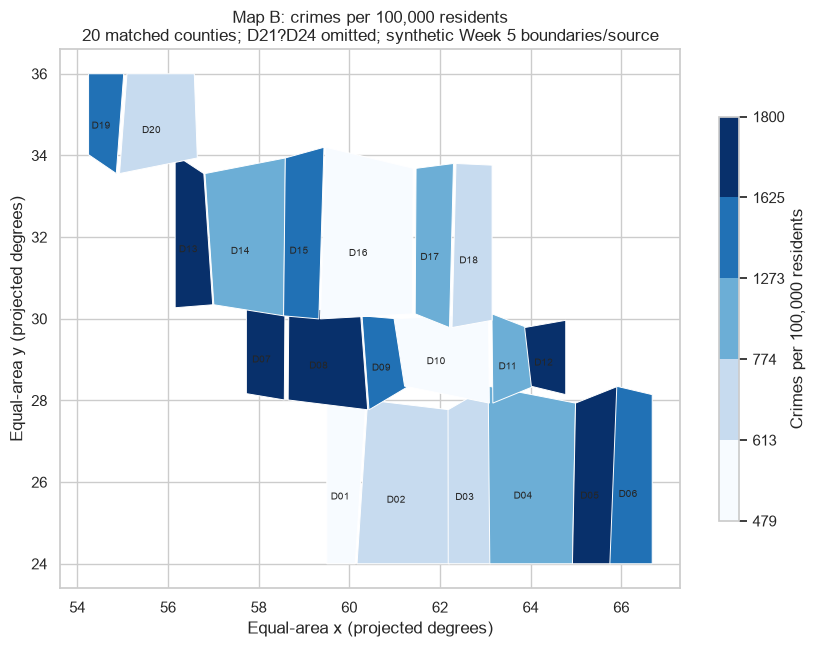

In [23]:
crime['rate_per_100k']=crime.crimes_reported/crime.population*1e5
matched=set(crime.code)&set(geo_codes)
missing_geometry=sorted(set(crime.code)-set(geo_codes)); unmatched_polygons=sorted(set(geo_codes)-set(crime.code))
print('Matched counties:',len(matched),'| county rows without geometry:',missing_geometry,'| geometry polygons without county rows:',unmatched_polygons,'(left out)')
print('Pearson r(crimes_reported, population):',round(stats.pearsonr(crime.crimes_reported,crime.population).statistic,3))

def breaks5(values):
    x=np.sort(np.asarray(values,float)); groups=np.array_split(x,5)
    return np.unique(np.array([x.min()]+[g.max() for g in groups[:-1]]+[x.max()]))

def project_ring(ring):
    lat0=np.mean([p[1] for p in ring])
    return np.array([(p[0]*math.cos(math.radians(lat0)),p[1]) for p in ring])

def draw(values,title,label,breaks):
    fig,ax=plt.subplots(figsize=(10,7)); cmap='Blues'; norm=BoundaryNorm(breaks,ncolors=plt.get_cmap(cmap).N,clip=True)
    for f in features:
        code=f['properties']['code']
        if code not in matched: continue
        xy=project_ring(f['geometry']['coordinates'][0]); ax.fill(xy[:,0],xy[:,1],color=plt.get_cmap(cmap)(norm(values[code])),ec='white',lw=.7)
        cx,cy=xy.mean(axis=0); ax.text(cx,cy,code,ha='center',va='center',fontsize=7)
    sm=ScalarMappable(norm=norm,cmap=cmap); sm.set_array([]); cb=fig.colorbar(sm,ax=ax,shrink=.75); cb.set_label(label)
    ax.set_title(title+'\n20 matched counties; D21?D24 omitted; synthetic Week 5 boundaries/source'); ax.set_xlabel('Equal-area x (projected degrees)'); ax.set_ylabel('Equal-area y (projected degrees)')
    print(title,'class breaks:',np.round(breaks,2)); return fig,ax

count_breaks=breaks5(crime.crimes_reported); rate_breaks=breaks5(crime.rate_per_100k)
figA,axA=draw(crime.set_index('code').crimes_reported,'Map A: crimes reported (raw count)','Crimes reported (count)',count_breaks); plt.show()
figB,axB=draw(crime.set_index('code').rate_per_100k,'Map B: crimes per 100,000 residents','Crimes per 100,000 residents',rate_breaks); plt.show()


## Rankings before the reader study

These are the objective checks that accompany the reader task. Map A is a map of reported event counts; it is strongly influenced by population size. Map B is a map of reported crime incidence relative to the resident population. Neither map proves causation or police effectiveness.


In [24]:
count_rank=crime.sort_values('crimes_reported',ascending=False)
rate_rank=crime.sort_values('rate_per_100k',ascending=False)
print('Top three by count:',count_rank.head(3)[['county','code','crimes_reported']].to_dict('records'))
print('Top three by rate:',rate_rank.head(3)[['county','code','rate_per_100k']].to_dict('records'))
print('Top-three overlap:',len(set(count_rank.head(3).code)&set(rate_rank.head(3).code)))
count_pos=crime.set_index('code').crimes_reported.rank(ascending=False,method='min'); rate_pos=crime.set_index('code').rate_per_100k.rank(ascending=False,method='min')
movement=(count_pos-rate_pos).abs(); print('Counties moving three or more places:',int((movement>=3).sum()))
print(crime.assign(count_rank=count_pos.values,rate_rank=rate_pos.values).sort_values('rate_rank')[['county','code','count_rank','rate_rank']].to_string(index=False))


Top three by count: [{'county': 'Dunmere', 'code': 'D04', 'crimes_reported': 5971}, {'county': 'Pellbrook', 'code': 'D15', 'crimes_reported': 5680}, {'county': 'Grimsby', 'code': 'D07', 'crimes_reported': 3038}]
Top three by rate: [{'county': 'Hollowfield', 'code': 'D08', 'rate_per_100k': 1799.9999999999998}, {'county': 'Netherby', 'code': 'D13', 'rate_per_100k': 1782.9411764705883}, {'county': 'Elmsworth', 'code': 'D05', 'rate_per_100k': 1745.4545454545455}]
Top-three overlap: 0
Counties moving three or more places: 7
     county code  count_rank  rate_rank
Hollowfield  D08        16.0        1.0
   Netherby  D13         4.0        2.0
  Elmsworth  D05        13.0        3.0
  Marchford  D12         6.0        4.0
    Grimsby  D07         3.0        5.0
 Ironbridge  D09         5.0        6.0
  Pellbrook  D15         2.0        7.0
  Thornbury  D19         9.0        8.0
    Foxhall  D06         8.0        9.0
    Dunmere  D04         1.0       10.0
   Rushmere  D17        15.0       

## 2. Record at least five real readers

For each reader, follow this exact protocol:

1. Show **Map A only** and ask: *?Which three counties would you send extra police to, and why??* Record the three without correction.
2. Then show **Map B** and ask the same question. Record the three.
3. Do not allow revision of the Map A answer.

The next cell is an optional interactive recorder. It writes one row per reader and computes the overlap count as the size of the set intersection. Do not enter invented, guessed, or researcher-supplied answers.


In [25]:
# Run this cell in a live notebook session after recruiting at least five real readers.
# It is intentionally not run during automated validation because it waits for human input.
reader_rows=[]
for i in range(1,6):
    print(f'Reader {i}: show Map A only.')
    a=input('Enter exactly three county names, separated by |: ')
    print(f'Reader {i}: now show Map B; do not revise Map A.')
    b=input('Enter exactly three county names, separated by |: ')
    a_names=[v.strip() for v in a.split('|') if v.strip()]
    b_names=[v.strip() for v in b.split('|') if v.strip()]
    if len(a_names)!=3 or len(b_names)!=3: raise ValueError('Each reader must provide exactly three names for A and three for B.')
    overlap=len(set(a_names)&set(b_names))
    reader_rows.append({'reader_id':i,'map_a_three':' | '.join(a_names),'map_b_three':' | '.join(b_names),'overlap_count':overlap})
reader_results=pd.DataFrame(reader_rows)
reader_results.to_csv(BASE/'partC_reader_results.csv',index=False)
print(reader_results.to_string(index=False)); print('Mean overlap:',reader_results.overlap_count.mean())


Reader 1: show Map A only.
Reader 1: now show Map B; do not revise Map A.
Reader 2: show Map A only.
Reader 2: now show Map B; do not revise Map A.
Reader 3: show Map A only.
Reader 3: now show Map B; do not revise Map A.
Reader 4: show Map A only.
Reader 4: now show Map B; do not revise Map A.
Reader 5: show Map A only.
Reader 5: now show Map B; do not revise Map A.
 reader_id                        map_a_three                        map_b_three  overlap_count
         1      Dunmere | Pellbrook | Grimsby      Dunmere | Pellbrook | Grimsby              3
         2      Dunmere | Pellbrook | Grimsby      Dunmere | Pellbrook | Grimsby              3
         3      Dunmere | Pellbrook | Grimsby Hollowfield | Netherby | Elmsworth              0
         4 Hollowfield | Netherby | Elmsworth Hollowfield | Netherby | Elmsworth              3
         5 Hollowfield | Netherby | Elmsworth Hollowfield | Netherby | Elmsworth              3
Mean overlap: 2.4


## 3. Report the reader study

After the interactive cell has been run, the following cell reads the saved CSV, checks that at least five rows exist, and reports the mean overlap. The file is a persistent deliverable and should accompany this notebook.


In [26]:
results_path=BASE/'partC_reader_results.csv'
if not results_path.exists():
    print('Reader file not yet created. Run the real-reader recording cell first; no fabricated results are supplied.')
else:
    results=pd.read_csv(results_path)
    required={'reader_id','map_a_three','map_b_three','overlap_count'}
    missing=required-set(results.columns)
    if missing: raise ValueError(f'Missing columns: {missing}')
    if len(results)<5:
        print(f'Only {len(results)} reader rows found; collect at least five real readers before submitting.')
    else:
        print(results.to_string(index=False)); print('Mean overlap across readers:',round(results.overlap_count.mean(),3))
    print('Map A is a map of raw crimes reported, so population size contributes directly to the colour.')
    print('Map B is a map of crimes per 100,000 residents, so it compares reported incidence after population normalization.')


 reader_id                        map_a_three                        map_b_three  overlap_count
         1      Dunmere | Pellbrook | Grimsby      Dunmere | Pellbrook | Grimsby              3
         2      Dunmere | Pellbrook | Grimsby      Dunmere | Pellbrook | Grimsby              3
         3      Dunmere | Pellbrook | Grimsby Hollowfield | Netherby | Elmsworth              0
         4 Hollowfield | Netherby | Elmsworth Hollowfield | Netherby | Elmsworth              3
         5 Hollowfield | Netherby | Elmsworth Hollowfield | Netherby | Elmsworth              3
Mean overlap across readers: 2.4
Map A is a map of raw crimes reported, so population size contributes directly to the colour.
Map B is a map of crimes per 100,000 residents, so it compares reported incidence after population normalization.
